# Bell State — Quantum Noise and Entanglement

In this notebook, I prepare a Bell state and compare how different noise channels affect its **fidelity**, **purity**, and **concurrence**. I also compare noise applied to only one qubit with noise applied to both qubits.

The calculations use density matrices and Kraus operators, so the results describe the noise channels directly without statistical shot noise. Readout noise is not included because it affects measurements rather than the density matrix itself.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, Kraus, state_fidelity
from IPython.display import display

## 1. Prepare the Bell state

We use $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$.

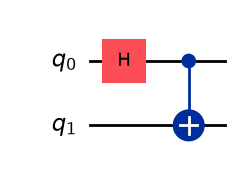

Ideal density matrix:
[[0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]]


In [2]:
#First we prepare the Bell state:
def create_bell_state():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    return qc

qc = create_bell_state()
display(qc.draw("mpl"))

rho_ideal = DensityMatrix.from_instruction(qc)
print("Ideal density matrix:")
print(np.round(rho_ideal.data, 3))

## 2. Define the noise channels

We use $p$ between 0 and 1 as the noise strength. For the bit-flip and phase-flip channels, $p$ is the probability of applying $X$ or $Z$. For the depolarizing channel, $p$ is the probability of choosing one of $X,Y,Z$ uniformly; thus $p=1$ is **not** a completely depolarizing channel under this convention.

For amplitude damping, $p$ is the excited-state decay probability. For phase damping, $p$ controls the decay of off-diagonal density-matrix elements.

Each channel is represented by Kraus operators $K_i$ satisfying $\sum_i K_i^\dagger K_i=I$.

In [3]:
#Pauli matrices:
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

#Noise channels using Kraus operators:
def noise_channel(noise_type, p):
    if not 0 <= p <= 1:
        raise ValueError("Noise strength p must be between 0 and 1")

    if noise_type == "Depolarizing":
        operators = [np.sqrt(1-p)*I, np.sqrt(p/3)*X,
                     np.sqrt(p/3)*Y, np.sqrt(p/3)*Z]

    elif noise_type == "Amplitude damping":
        operators = [np.array([[1, 0], [0, np.sqrt(1-p)]], dtype=complex),
                     np.array([[0, np.sqrt(p)], [0, 0]], dtype=complex)]

    elif noise_type == "Phase damping":
        operators = [np.array([[1, 0], [0, np.sqrt(1-p)]], dtype=complex),
                     np.array([[0, 0], [0, np.sqrt(p)]], dtype=complex)]

    elif noise_type == "Bit flip":
        operators = [np.sqrt(1-p)*I, np.sqrt(p)*X]

    elif noise_type == "Phase flip":
        operators = [np.sqrt(1-p)*I, np.sqrt(p)*Z]

    else:
        raise ValueError("Unknown noise type")

    return Kraus(operators)

noise_types = ["Depolarizing", "Amplitude damping", "Phase damping",
               "Bit flip", "Phase flip"]

#Check trace preservation:
for noise_type in noise_types:
    operators = noise_channel(noise_type, 0.3).data
    check = sum(k.conj().T @ k for k in operators)
    assert np.allclose(check, I)
print("All channels satisfy the Kraus completeness relation.")

All channels satisfy the Kraus completeness relation.


## 3. Apply noise to one qubit or both qubits

For the two-qubit case, the same independent single-qubit channel acts on each qubit. The noise is applied **after** preparing the Bell state.

In [4]:
def apply_noise(noise_type, p, noisy_qubits):
    rho = DensityMatrix(rho_ideal.data.copy())
    channel = noise_channel(noise_type, p)

    for qubit in noisy_qubits:
        rho = rho.evolve(channel, qargs=[qubit])

    return rho

#Example: amplitude damping on one qubit:
rho_one = apply_noise("Amplitude damping", 0.3, [0])

#And on both qubits:
rho_both = apply_noise("Amplitude damping", 0.3, [0, 1])

print("One qubit:")
print(np.round(rho_one.data, 3))
print("\nBoth qubits:")
print(np.round(rho_both.data, 3))

One qubit:
[[0.5  +0.j 0.   +0.j 0.   +0.j 0.418+0.j]
 [0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j]
 [0.   +0.j 0.   +0.j 0.15 +0.j 0.   +0.j]
 [0.418+0.j 0.   +0.j 0.   +0.j 0.35 +0.j]]

Both qubits:
[[0.545+0.j 0.   +0.j 0.   +0.j 0.35 +0.j]
 [0.   +0.j 0.105+0.j 0.   +0.j 0.   +0.j]
 [0.   +0.j 0.   +0.j 0.105+0.j 0.   +0.j]
 [0.35 +0.j 0.   +0.j 0.   +0.j 0.245+0.j]]


## 4. Calculate fidelity, purity and concurrence

Fidelity compares the noisy state with the ideal Bell state:

$$F=\langle\Phi^+|\rho|\Phi^+\rangle.$$

Purity is $P=\mathrm{Tr}(\rho^2)$. A pure state has $P=1$; a maximally mixed two-qubit state has $P=1/4$.

Concurrence is an entanglement measure for two qubits:

$$C(\rho)=\max(0,\lambda_1-\lambda_2-\lambda_3-\lambda_4),$$

where the $\lambda_i$ are the descending square roots of the eigenvalues of $\rho\tilde{\rho}$, with $\tilde{\rho}=(Y\otimes Y)\rho^*(Y\otimes Y)$.

In [5]:
def calculate_concurrence(rho):
    rho_matrix = rho.data
    YY = np.kron(Y, Y)
    rho_tilde = YY @ np.conj(rho_matrix) @ YY

    eigenvalues = np.linalg.eigvals(rho_matrix @ rho_tilde)
    eigenvalues = np.maximum(np.real(eigenvalues), 0)
    lambdas = np.sort(np.sqrt(eigenvalues))[::-1]

    return float(np.clip(lambdas[0] - sum(lambdas[1:]), 0, 1))


def calculate_quantities(rho):
    fidelity = float(state_fidelity(rho_ideal, rho))
    purity = float(np.real(np.trace(rho.data @ rho.data)))
    concurrence = calculate_concurrence(rho)
    return fidelity, purity, concurrence

print("Ideal:", calculate_quantities(rho_ideal))
print("One noisy qubit:", calculate_quantities(rho_one))
print("Two noisy qubits:", calculate_quantities(rho_both))

Ideal: (0.9999999999999998, 0.9999999999999996, 0.9999999999999994)
One noisy qubit: (0.8433300132670378, 0.7449999999999997, 0.8366600265340752)
Two noisy qubits: (0.7450000018606595, 0.6240999999999997, 0.49000000000000055)


## 5. Compare all noise channels

For each noise channel, we calculate the three quantities for different noise strengths. The dashed curves correspond to noise acting on both qubits.

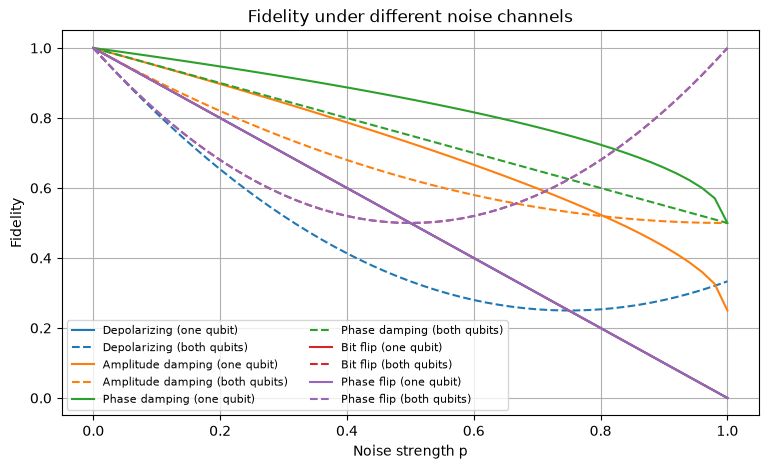

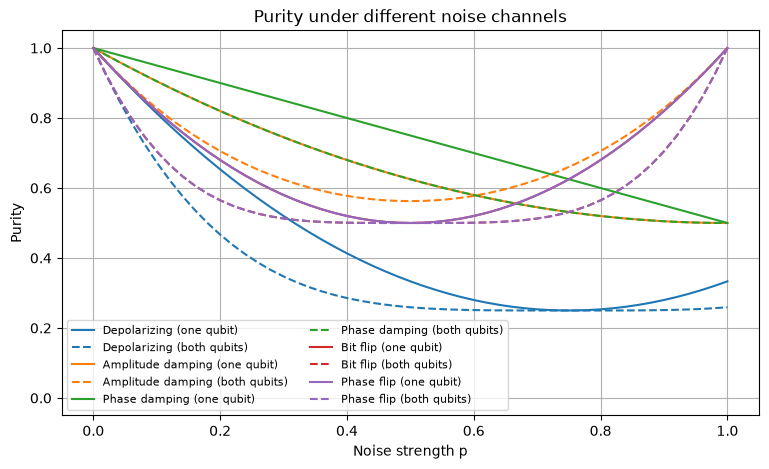

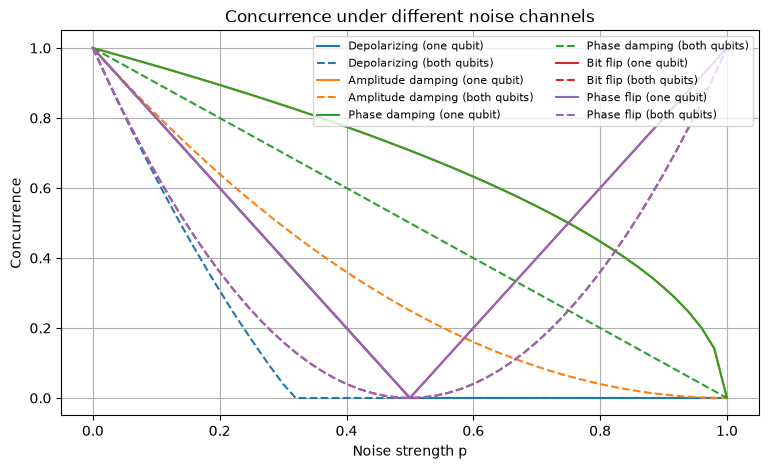

In [6]:
p_values = np.linspace(0, 1, 51)

results = {}
for noise_type in noise_types:
    one_qubit = []
    both_qubits = []

    for p in p_values:
        rho_1 = apply_noise(noise_type, p, [0])
        rho_2 = apply_noise(noise_type, p, [0, 1])

        one_qubit.append(calculate_quantities(rho_1))
        both_qubits.append(calculate_quantities(rho_2))

    results[noise_type] = {"one": np.array(one_qubit),
                           "both": np.array(both_qubits)}

#Plot each quantity separately:
quantity_names = ["Fidelity", "Purity", "Concurrence"]

for index, quantity in enumerate(quantity_names):
    plt.figure(figsize=(9, 5))

    for noise_type in noise_types:
        line, = plt.plot(p_values, results[noise_type]["one"][:, index],
                         label=noise_type + " (one qubit)")
        plt.plot(p_values, results[noise_type]["both"][:, index],
                 "--", color=line.get_color(), label=noise_type + " (both qubits)")

    plt.xlabel("Noise strength p")
    plt.ylabel(quantity)
    plt.title(quantity + " under different noise channels")
    plt.ylim(-0.05, 1.05)
    plt.grid(True)
    plt.legend(fontsize=8, ncol=2)
    plt.show()

## 6. Focus on amplitude damping

Here we compare noise acting on one or both qubits in a single channel. This is useful because amplitude damping is not symmetric between $|0\rangle$ and $|1\rangle$.

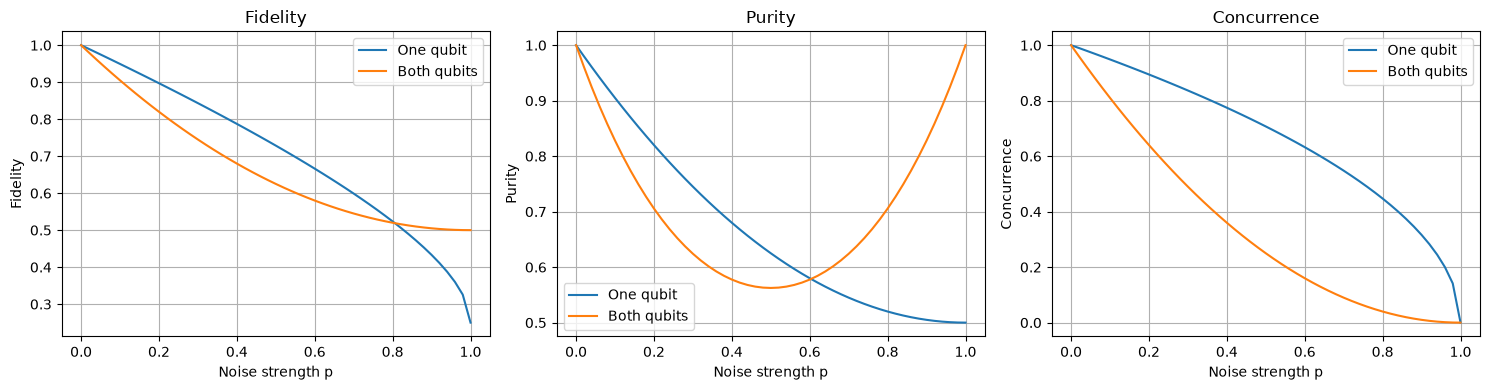

In [7]:
noise_type = "Amplitude damping"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for index, quantity in enumerate(quantity_names):
    axes[index].plot(p_values, results[noise_type]["one"][:, index],
                     label="One qubit")
    axes[index].plot(p_values, results[noise_type]["both"][:, index],
                     label="Both qubits")
    axes[index].set_xlabel("Noise strength p")
    axes[index].set_ylabel(quantity)
    axes[index].set_title(quantity)
    axes[index].grid(True)
    axes[index].legend()

plt.tight_layout()
plt.show()

## 7. Density matrix visualization

The real and imaginary parts of the density matrix show how the Bell-state populations and coherence change after amplitude damping.

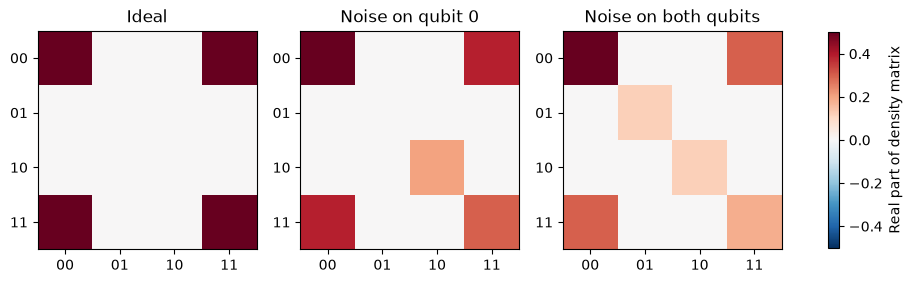

Maximum imaginary component: 0.0


In [8]:
p = 0.4
rho_one = apply_noise("Amplitude damping", p, [0])
rho_both = apply_noise("Amplitude damping", p, [0, 1])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, rho, title in zip(axes,
                          [rho_ideal, rho_one, rho_both],
                          ["Ideal", "Noise on qubit 0", "Noise on both qubits"]):
    image = ax.imshow(np.real(rho.data), vmin=-0.5, vmax=0.5, cmap="RdBu_r")
    ax.set_title(title)
    ax.set_xticks(range(4), ["00", "01", "10", "11"])
    ax.set_yticks(range(4), ["00", "01", "10", "11"])

fig.colorbar(image, ax=axes, shrink=0.8, label="Real part of density matrix")
plt.show()

print("Maximum imaginary component:",
      max(np.max(np.abs(np.imag(rho.data))) for rho in [rho_ideal, rho_one, rho_both]))

## 8. Check the results

A few checks help make sure the code behaves as expected. Note that some noise channels are **not monotonic** over the full range $0\le p\le1$. For example, a bit flip with $p=1$ is a deterministic $X$ gate, not random noise.

In [9]:
#No noise should give the ideal Bell state:
for noise_type in noise_types:
    assert np.allclose(apply_noise(noise_type, 0, [0, 1]).data, rho_ideal.data)

#All calculated density matrices must be normalized:
for noise_type in noise_types:
    for p in [0, 0.2, 0.5, 1]:
        for noisy_qubits in [[0], [0, 1]]:
            rho = apply_noise(noise_type, p, noisy_qubits)
            assert np.isclose(np.trace(rho.data), 1)
            assert np.allclose(rho.data, rho.data.conj().T)
            assert np.min(np.linalg.eigvalsh(rho.data)) > -1e-10

#For a Bell state, phase flip on one qubit with p=0.5 destroys entanglement:
rho_test = apply_noise("Phase flip", 0.5, [0])
assert np.isclose(calculate_concurrence(rho_test), 0, atol=1e-8)

#Amplitude damping on both qubits with p=1 gives |00>, a pure separable state:
rho_test = apply_noise("Amplitude damping", 1, [0, 1])
fidelity, purity, concurrence = calculate_quantities(rho_test)
assert np.isclose(fidelity, 0.5)
assert np.isclose(purity, 1)
assert np.isclose(concurrence, 0)

print("All checks passed.")

All checks passed.


## Conclusion

This notebook compares the effects of five quantum noise channels on a Bell state. Fidelity measures similarity to the initial state, purity measures mixedness, and concurrence measures entanglement. Comparing one-qubit and two-qubit noise helps distinguish how local errors affect the full entangled system.

The simulations apply idealized channels directly to density matrices. They do not model finite-shot measurement uncertainty, gate-specific device calibration, or error mitigation.